In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import (train_test_split, StratifiedKFold, 
                                     cross_validate, cross_val_predict)
from sklearn.metrics import(accuracy_score, recall_score, 
                            precision_score, roc_auc_score, 
                            silhouette_score, ConfusionMatrixDisplay, 
                            RocCurveDisplay)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# 1)

In [2]:
framingham = pd.read_csv('../../data/framingham.csv')

features = ['male', 'age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 
            'BMI', 'heartRate', 'glucose']
target = 'TenYearCHD'

fram = framingham.dropna(subset=features + [target]).reset_index(drop=True)
X = fram[features]
y = fram[target]

X_train, X_test, y_train_, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=113
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=224)

def make_knn(k):
    return Pipeline([('scale', StandardScaler()), 
                     ('model', KNeighborsClassifier(n_neighbors=k))])

print(f"{len(framingham)} patients, {len(fram)} with complete data")

4240 patients, 3802 with complete data


### 1)

A model that predicts no CHD for everyone doesn't catch 1 heart disease case, so its recall is 0. It gives every patient the same score so its ROC AUC is 0.5 

### 2)

,k,accuracy,balanced_acc,auc,auc_sd,auc_se
0,1,0.7715,0.5470,0.5470,0.0188,0.0084
1,5,0.8333,0.5404,0.6131,0.0271,0.0121
2,11,0.8451,0.5193,0.6422,0.0237,0.0106
3,25,0.8461,0.5014,0.6678,0.0260,0.0116
4,51,0.8468,0.5000,0.6811,0.0207,0.0092
5,75,0.8468,0.5000,0.6901,0.0244,0.0109
6,101,0.8468,0.5000,0.6966,0.0219,0.0098
7,151,0.8468,0.5000,0.7001,0.0196,0.0088
8,201,0.8468,0.5000,0.7053,0.0178,0.0080
9,251,0.8468,0.5000,0.7086,0.0240,0.0107


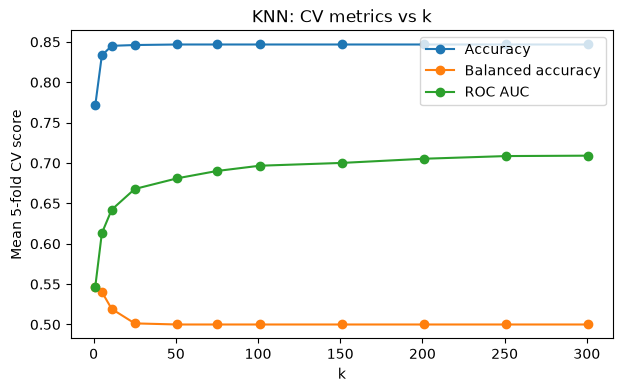

best AUC: k=301 (0.7091, SE 0.0109); 1-SE threshold 0.6982; smallest k within 1 SE: 151
k=11: predicts CHD for 51 of 3041 training patients (actual CHD: 466)
k=51: predicts CHD for 0 of 3041 training patients (actual CHD: 466)
k=151: predicts CHD for 0 of 3041 training patients (actual CHD: 466)


In [3]:
K = [1, 5, 11, 25, 51, 75, 101, 151, 201, 251, 301]
rows = []
for k in K:
    r = cross_validate(make_knn(k), X_train, y_train_, cv=cv, scoring=["accuracy", "balanced_accuracy", "roc_auc"])
    rows.append(dict(k=k, accuracy=r['test_accuracy'].mean(), balanced_acc=r['test_balanced_accuracy'].mean(),
                     auc=r['test_roc_auc'].mean(), auc_sd=r['test_roc_auc'].std(ddof=1)))
res = pd.DataFrame(rows)
res['auc_se'] = res.auc_sd / np.sqrt(5)
display(res.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
for c, l in [('accuracy', 'Accuracy'), ('balanced_acc', 'Balanced accuracy'), ('auc', 'ROC AUC')]:
    ax.plot(res.k, res[c], marker='o', label=l)
ax.set_xlabel('k'); ax.set_ylabel('Mean 5-fold CV score'); ax.legend(); ax.set_title('KNN: CV metrics vs k')
plt.show()

best = res.loc[res.auc.idxmax()]
thr = best.auc - best.auc_se
print(f"best AUC: k={int(best.k)} ({best.auc:.4f}, SE {best.auc_se:.4f}); 1-SE threshold {thr:.4f}; "
      f"smallest k within 1 SE: {int(res[res.auc >= thr].k.min())}")

for k in [11, 51, 151]:
    p = cross_val_predict(make_knn(k), X_train, y_train_, cv=cv)
    print(f"k={k}: predicts CHD for {p.sum()} of {len(p)} training patients (actual CHD: {y_train_.sum()})")

- a) Accuracy is 0.8468 for every k 51 and larger. The out of fold predictions explain why: As k grows, each patient's neighbors is averaged over more people, and the share of CHD neighbors goes toward the 15% base rate. Once no neighborhood has more than half CHD, the model predicts no CHD for everyone
- b) Balanced accuracy falls from 0.547 at k = 1 to exactly 0.500 for k = 51 and up. Once the model predicts no CHD for everyone, recall for CHD is 0 and recall for no-CHD is 1, so the average is 0.5
- c) AUC keeps rising with k, and the best is k = 301 (0.7091). The one SE cutoff is 0.6982. k = 101 just misses and k = 151 clears it, so it picks k = 151

### 3)

max out-of-fold probability: 0.404; patients with p >= 0.5: 0; with p >= 0.2: 449
threshold 0.5: accuracy 0.847, recall 0.000, precision 0.000
threshold 0.2: accuracy 0.795, recall 0.313, precision 0.325


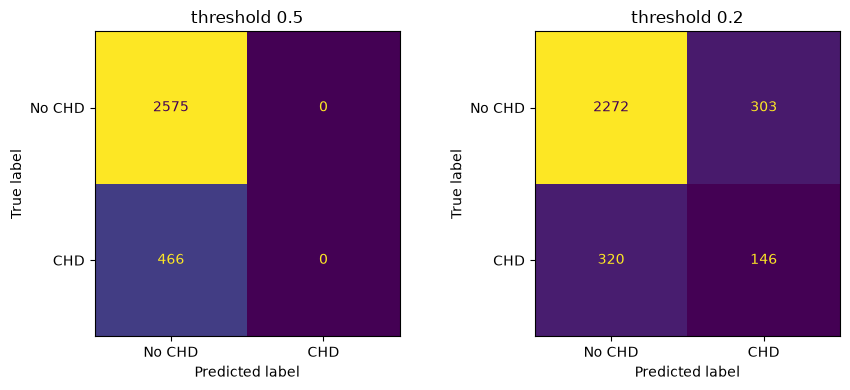

In [4]:
k = 151
proba = cross_val_predict(make_knn(k), X_train, y_train_, cv=cv, method="predict_proba")[:, 1]
print(f"max out-of-fold probability: {proba.max():.3f}; patients with p >= 0.5: {(proba >= 0.5).sum()}; with p >= 0.2: {(proba >= 0.2).sum()}")

fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for ax, t in zip(axs, [0.5, 0.2]):
    pred = (proba >= t).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_train_, pred, ax=ax, colorbar=False, display_labels=['No CHD', 'CHD'])
    ax.set_title(f'threshold {t}')
    print(f"threshold {t}: accuracy {accuracy_score(y_train_, pred):.3f}, recall {recall_score(y_train_, pred):.3f}, "
          f"precision {precision_score(y_train_, pred, zero_division=0):.3f}")
plt.tight_layout()

- a) With k = 151 the probability is the share of 151 neighbors with CHD, and the largest out of fold probability is only 0.4. No patient reaches 0.5, so predict() never guesses CHD
- b) The lower threshold is more useful for a doctor because it flags 449 patients and catches about 31% of the positives at .2 vs none at .5. Missing a future CHD case is usually costlier than an extra follow-up visit so the lower accuracy is worth the increase in recall. Choosing k by AUC works well because AUC doesn't have a threshold: it measures how well the model ranks patients. Choosing the threshold depends on the cost of a false negative vs false positive, which is a decision about circumstances and not a factor in the model.

### 4)

test ROC AUC 0.7664
threshold 0.2: accuracy 0.798, recall 0.436, precision 0.367 (flagged 139)


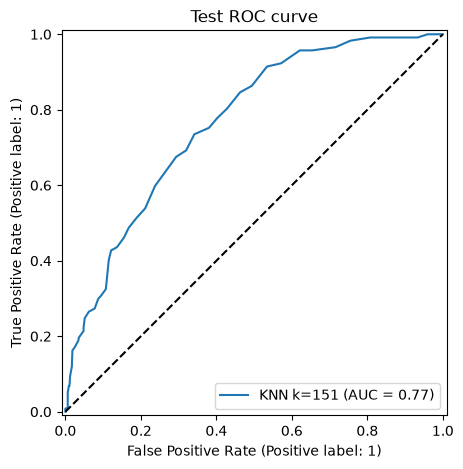

SE of test AUC: 0.027


In [5]:
final = make_knn(151).fit(X_train, y_train_)
p_test = final.predict_proba(X_test)[:, 1]
auc_test = roc_auc_score(y_test, p_test)
pred = (p_test >= 0.2).astype(int)
print(f"test ROC AUC {auc_test:.4f}")
print(f"threshold 0.2: accuracy {accuracy_score(y_test, pred):.3f}, recall {recall_score(y_test, pred):.3f}, precision {precision_score(y_test, pred):.3f} (flagged {pred.sum()})")

fig, ax = plt.subplots(figsize=(5, 5))
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax, name='KNN k=151'); ax.plot([0, 1], [0, 1], 'k--')
ax.set_title('Test ROC curve'); plt.show()

n1, n0 = int(y_test.sum()), int((y_test == 0).sum())
q1, q2 = auc_test/(2-auc_test), 2*auc_test**2/(1+auc_test)
se = np.sqrt((auc_test*(1-auc_test) + (n1-1)*(q1-auc_test**2) + (n0-1)*(q2-auc_test**2)) / (n1*n0))
print(f"SE of test AUC: {se:.3f}")

- a) Test ROC AUC is 0.766. At a 0.2 threshold accuracy is 0.798, recall 0.436, and precision 0.367
- b) The test AUC (0.766) is higher than the CV AUC (0.700,). With 117 CHD cases in the test set, the standard error of the test AUC is 0.027 so the gap of is roughly two standard errors. It doesn't change the conclusion, KNN only gives a decent ability to rank patients. It wouldn't be appropriate to go back and choose a different k since test set has been used so it would leak test information into the model choice and the AUC wouldn't be an honest estimate

# Part 2

In [6]:
auto = pd.read_csv("../../data/Auto.csv", na_values="?").dropna().reset_index(drop=True)

auto_feats = ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']
Xa = auto[auto_feats]

scaler = StandardScaler()
Xa_s = scaler.fit_transform(Xa)
auto.shape

(392, 9)

### 1)

,mean,std,min,max
mpg,23.45,7.81,9.0,46.6
displacement,194.41,104.64,68.0,455.0
horsepower,104.47,38.49,46.0,230.0
weight,2977.58,849.40,1613.0,5140.0
acceleration,15.54,2.76,8.0,24.8


,count,min,max
raw,,,
0,90,3693,5140
1,180,1613,2694
2,122,2700,3672


,mpg,displacement,horsepower,weight,acceleration
raw,,,,,
0,14.6,344.1,157.8,4236.3,13.5
1,29.7,107.2,77.2,2222.8,16.3
2,20.8,212.6,105.4,3162.6,15.9


[Text(0.5, 0, 'weight'),
 Text(0, 0.5, 'mpg'),
 Text(0.5, 1.0, 'K-means (K=3) on UNscaled features')]

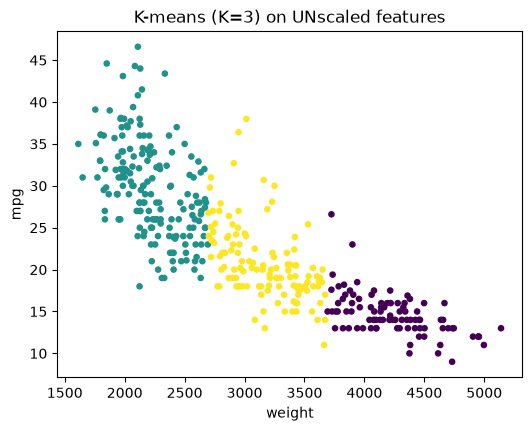

In [7]:
display(Xa.agg(['mean', 'std', 'min', 'max']).T.round(2))

km_raw = KMeans(n_clusters=3, n_init=20, random_state=0).fit(Xa)
auto['raw'] = km_raw.labels_
display(auto.groupby('raw').weight.agg(['count', 'min', 'max']))
display(auto.groupby('raw')[auto_feats].mean().round(1))
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(auto.weight, auto.mpg, c=auto.raw, cmap='viridis', s=14)
ax.set(xlabel='weight', ylabel='mpg', title='K-means (K=3) on UNscaled features')

- b) With unscaled data the K means pretty much sorts the cars by weight.The distance is dominated by weight because its values differ by much more than mpg and acceleration, so acceleration and mpg barely affect which cluster a car is put in

### 2)

,K,WCSS,avg_silhouette
0,1,1960.000,NaN
1,2,834.029,0.524
2,3,561.671,0.382
3,4,451.322,0.360
4,5,388.114,0.348
5,6,333.871,0.322
6,7,300.501,0.313
7,8,274.951,0.298
8,9,257.563,0.277
9,10,239.375,0.276


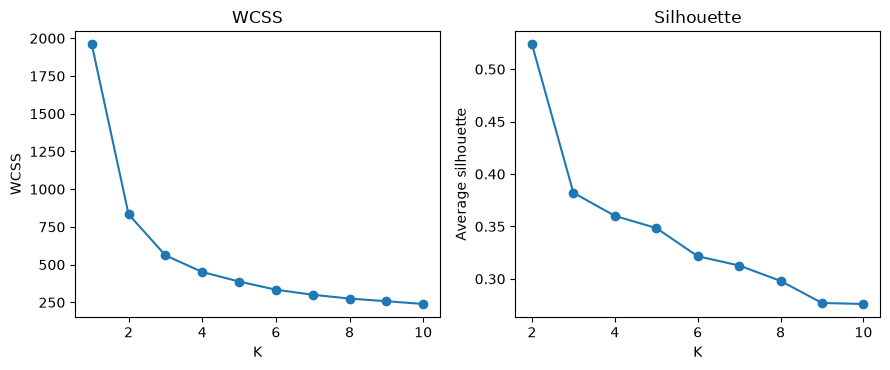

In [8]:
W = []
S = []
for K in range(1, 11):
    m = KMeans(n_clusters=K, n_init=20, random_state=0).fit(Xa_s)
    W.append(m.inertia_)
    S.append(silhouette_score(Xa_s, m.labels_) if K >= 2 else np.nan)
q2 = pd.DataFrame({'K': range(1, 11), 'WCSS': W, 'avg_silhouette': S})
display(q2.round(3))
fig, axs = plt.subplots(1, 2, figsize=(9, 3.8))
axs[0].plot(q2.K, q2.WCSS, marker='o'); axs[0].set(xlabel='K', ylabel='WCSS', title='WCSS')
axs[1].plot(q2.K[1:], q2.avg_silhouette[1:], marker='o'); axs[1].set(xlabel='K', ylabel='Average silhouette', title='Silhouette')
plt.tight_layout(); plt.show()

- a) Either 2 or 3, I'd lean towards 3
- b) K = 10
- c) I'd choose K = 3 because it balances between the flattening of the WCSS elbow and the silhouette score. 

### 3)

In [9]:
k3 = KMeans(n_clusters=3, n_init=20, random_state=0).fit(Xa_s)
auto['k3'] = k3.labels_
t = auto.groupby('k3')[auto_feats].mean().round(1)
t.insert(0, 'n_cars', auto.k3.value_counts().sort_index())
display(t)
display(pd.crosstab(auto.k3, auto.cylinders))
display(pd.crosstab(auto.k3, auto.origin))
display(auto.groupby('k3').year.mean().round(2))

,n_cars,mpg,displacement,horsepower,weight,acceleration
k3,,,,,,
0,147,31.6,103.2,72.9,2189.8,16.8
1,148,21.2,184.3,98.3,2995.6,16.2
2,97,14.5,348.0,161.8,4144.0,12.6


cylinders,3,4,5,6,8
k3,,,,,
0,0,144,1,2,0
1,4,55,2,80,7
2,0,0,0,1,96


origin,1,2,3
k3,,,
0,44,45,58
1,104,23,21
2,97,0,0


k3
0    77.63
1    75.88
2    73.63
Name: year, dtype: float64

- b) Cluster 2 is entirely American and all but one of them are 8 cylinder engines. The 4 cylinder cars are in groups 0 and 1 with none are in cluster 2, while all of cluster 0 is is four cylinder cars except for 3. The clustering seems to line up pretty close with the number of cylinders so it lines up pretty close with that

### 4)

In [10]:
k2 = KMeans(n_clusters=2, n_init=20, random_state=0).fit(Xa_s)
auto['k2'] = k2.labels_
display(pd.crosstab(auto.k2, auto.k3))
display(pd.crosstab(auto.k2, auto.cylinders))
t = auto.groupby('k2')[auto_feats].mean().round(1); t.insert(0, 'n_cars', auto.k2.value_counts().sort_index())
display(t)

k3,0,1,2
k2,,,
0,0,4,97
1,147,144,0


cylinders,3,4,5,6,8
k2,,,,,
0,0,0,0,2,99
1,4,199,3,81,4


,n_cars,mpg,displacement,horsepower,weight,acceleration
k2,,,,,,
0,101,14.7,345.5,160.1,4119.8,12.7
1,291,26.5,142.0,85.1,2581.1,16.5


- a) K = 2 separates 8 cylinder cars/trucks from the rest of the vehicles
- b) Close but not exactly. K = 3 clusters 0 and 2 each sit entirely inside one K = 2 cluster, but the K = 3 middle cluster is split. K means doesn't have to give nested solutions since each K starts from fresh starting centers that minimizes WCSS for that K

# Part 3

### 1) 

In [11]:
labs = {}
rows = []
for l in ['single', 'complete', 'average', 'ward']:
    lab = AgglomerativeClustering(n_clusters=3, linkage=l).fit_predict(Xa_s); labs[l] = lab
    rows.append((l, np.bincount(lab).tolist(), round(silhouette_score(Xa_s, lab), 3)))
rows.append(('K-means (K=3)', np.bincount(auto.k3).tolist(), round(silhouette_score(Xa_s, auto.k3), 3)))
display(pd.DataFrame(rows, columns=['method', 'cluster sizes', 'avg silhouette']))

s = labs['single']
small = np.isin(s, [c for c in range(3) if np.bincount(s)[c] < 10])
display(auto.loc[small, ['name', 'year', 'cylinders', 'origin'] + auto_feats])
display(pd.DataFrame(Xa_s, columns=auto_feats)[small].round(2))     # z-scores
display(auto[auto_feats].describe().loc[['mean', 'min', 'max']].round(1))

a = labs['average']; tiny = a == np.bincount(a).argmin()
display(auto.loc[tiny, ['name', 'year', 'cylinders', 'origin'] + auto_feats])

,method,cluster sizes,avg silhouette
0,single,"[390, 1, 1]",-0.059
1,complete,"[97, 95, 200]",0.343
2,average,"[291, 97, 4]",0.422
3,ward,"[212, 99, 81]",0.374
4,K-means (K=3),"[147, 148, 97]",0.382


,name,year,cylinders,origin,mpg,displacement,horsepower,weight,acceleration
13,buick estate wagon (sw),70,8,1,14.0,455.0,225.0,3086,10.0
381,oldsmobile cutlass ciera (diesel),82,6,1,38.0,262.0,85.0,3015,17.0


,mpg,displacement,horsepower,weight,acceleration
13,-1.21,2.49,3.14,0.13,-2.01
381,1.87,0.65,-0.51,0.04,0.53


,mpg,displacement,horsepower,weight,acceleration
mean,23.4,194.4,104.5,2977.6,15.5
min,9.0,68.0,46.0,1613.0,8.0
max,46.6,455.0,230.0,5140.0,24.8


,name,year,cylinders,origin,mpg,displacement,horsepower,weight,acceleration
242,volkswagen rabbit custom diesel,78,4,2,43.1,90.0,48.0,1985,21.5
323,vw rabbit c (diesel),80,4,2,44.3,90.0,48.0,2085,21.7
324,vw dasher (diesel),80,4,2,43.4,90.0,48.0,2335,23.7
388,vw pickup,82,4,2,44.0,97.0,52.0,2130,24.6


- a) Single linkage is extremely lopsided (390/1/1), and average linkage is also pretty lopsided (291/97/4)
- b) The two single linkage cars are the Buick Estate Wagon and the Oldsmobile Cutlass Ciera. The Buick has a 455 cubic inch engine, 225 hp (z = +3.1) and 10.0 s acceleration (z = −2.0), but weighs only 3086 lbs (z = +0.13). The other 455 engine cars in the data weigh over 4300 lbs, so it's an insane outlier compared to other cars with similar stats. The Oldsmobile gets 38 mpg (z = +1.9) with a 262 ci, 3,015 lb body, which is a lot more efficient than any other car its size. Both have a weird combination of features with no other similar counterparts so single linkage never merges them to a main group and the points that are isolated are the last to join
- c) Average linkage has the highest silhouette but it doesn't have the best cluster. It has 291/97/4, and the small cluster is just four VW diesels which are outliers. The silhouette score rewards separating an outlier group well but it says nothing about whether the groups are useful. Ward or K means give more balanced groups that are easier to interpret even though their silhouettes are lower

### 2)

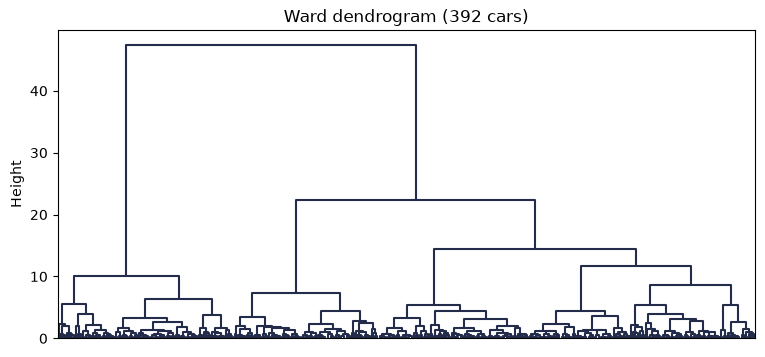

eight largest merge heights: [47.39 22.43 14.5  11.64 10.08  8.56  7.27  6.33]
jumps between consecutive merges: [24.97  7.93  2.86  1.55  1.52  1.29  0.94]


,K,avg silhouette,cluster sizes
0,2,0.525,"[99, 293]"
1,3,0.374,"[99, 81, 212]"
2,4,0.313,"[99, 81, 85, 127]"
3,5,0.327,"[99, 81, 85, 57, 70]"
4,6,0.291,"[32, 67, 81, 85, 57, 70]"
5,7,0.295,"[32, 67, 81, 85, 57, 50, 20]"
6,8,0.263,"[32, 67, 38, 43, 85, 57, 50, 20]"


In [12]:
Z = linkage(Xa_s, method="ward")
fig, ax = plt.subplots(figsize=(9, 4))
dendrogram(Z, no_labels=True, ax=ax, color_threshold=0, above_threshold_color='#232D4B')
ax.set(title='Ward dendrogram (392 cars)', ylabel='Height'); plt.show()

h = Z[-8:, 2][::-1]
print("eight largest merge heights:", h.round(2))
print("jumps between consecutive merges:", (h[:-1] - h[1:]).round(2))
ward_sil = []
for K in range(2, 9):
    f = fcluster(Z, t=K, criterion="maxclust")
    ward_sil.append((K, round(silhouette_score(Xa_s, f), 3), np.bincount(f)[1:].tolist()))
display(pd.DataFrame(ward_sil, columns=['K', 'avg silhouette', 'cluster sizes']))

- a) The largest jump is from 47.39 to 22.43. Cutting just below the top merge gives 2 clusters. The next largest is 22.43 to 14.50 which gives 3 clusters. The Ward silhouettes agree with K means in Part 2. K = 2 has the best silhouette in both and there is a smaller second structure at K = 3

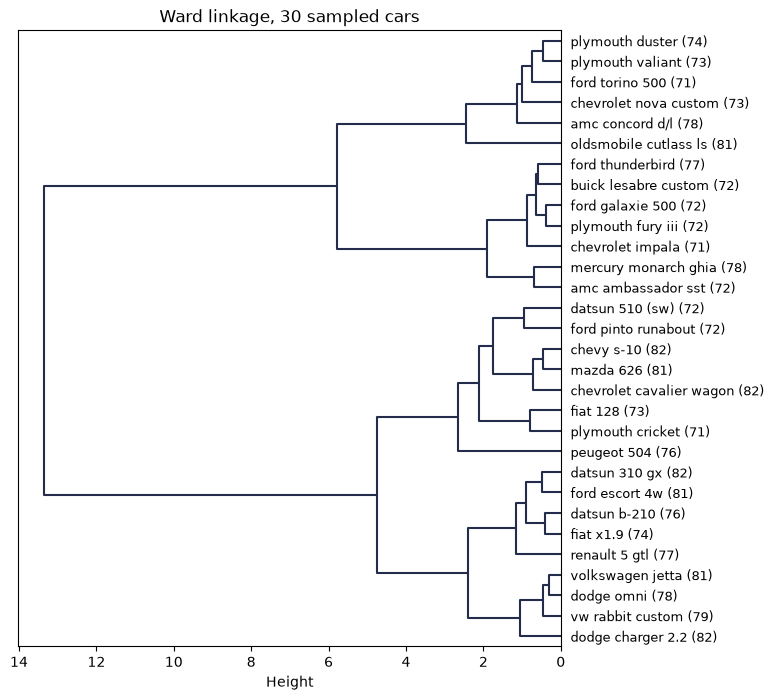

first merge: ['dodge omni (78)', 'volkswagen jetta (81)'] at height 0.296


,name,year,cylinders,origin,cluster,mpg,displacement,horsepower,weight,acceleration
60,ford pinto runabout,72,4,1,1,21.0,122.0,86.0,2226,16.5
55,plymouth cricket,71,4,1,1,26.0,91.0,70.0,1955,20.5
116,fiat 128,73,4,2,1,29.0,68.0,49.0,1867,19.5
207,peugeot 504,76,4,2,1,19.0,120.0,88.0,3270,21.9
149,fiat x1.9,74,4,2,1,31.0,79.0,67.0,2000,16.0
202,datsun b-210,76,4,3,1,32.0,85.0,70.0,1990,17.0
80,datsun 510 (sw),72,4,3,1,28.0,97.0,92.0,2288,17.0
391,chevy s-10,82,4,1,1,31.0,119.0,82.0,2720,19.4
353,mazda 626,81,4,3,1,31.6,120.0,74.0,2635,18.3
363,chevrolet cavalier wagon,82,4,1,1,27.0,112.0,88.0,2640,18.6


,mpg,displacement,horsepower,weight,acceleration
cluster,,,,,
1,30.3,100.9,74.1,2245.4,17.1
2,15.6,332.3,151.6,4078.9,13.0
3,19.6,255.2,102.2,3323.0,16.8


In [13]:
#Q2b: 30 cars sampled at random, labeled by name and model year.
rng = np.random.default_rng(6021)
samp = np.sort(rng.choice(len(auto), 30, replace=False))
names = (auto.loc[samp, 'name'] + " (" + auto.loc[samp, 'year'].astype(str) + ")").to_list()

fig, ax = plt.subplots(figsize = (7, 8))     # note: the handout's plt.subplot is a typo for plt.subplots
Zs = linkage(Xa_s[samp], method='ward')
dendrogram(Zs, labels=names, orientation='left',
           color_threshold=0, above_threshold_color='#232D4B', leaf_font_size=9, ax=ax)
ax.set(xlabel='Height', title='Ward linkage, 30 sampled cars'); plt.show()

print("first merge:", [names[int(i)] for i in Zs[0, :2]], "at height", round(Zs[0, 2], 3))
f3 = fcluster(Zs, 3, 'maxclust')
d = auto.loc[samp].assign(cluster=f3)[['name', 'year', 'cylinders', 'origin', 'cluster'] + auto_feats]
display(d.sort_values('cluster'))
display(d.groupby('cluster')[auto_feats].mean().round(1))

- b) The first two cars merged are the Dodge Omni and the Volkswagen Jetta. Cutting the tree into 3 clusters gives: (1) - Super efficient cars with high acceleration and low weight/hp/displacement; (2) - Super heavy and inefficient vehicles (likely trucks) that have a high displacement but low acceleration; (3) - The middle ground. Efficiency, displacement, hoursepower, weight, and acceleration all between groups 1 and 2. Nothing seems too out of place, except maybe the peugeot 504 which has much worse mpg and higher weight than class 1

### 3) 

In [14]:
auto['w2'] = fcluster(Z, 2, 'maxclust'); auto['w3'] = fcluster(Z, 3, 'maxclust')
for a_, b_ in [('w2', 'k2'), ('w3', 'k3')]:
    ct = pd.crosstab(auto[a_], auto[b_]); display(ct)
    print(f"{a_} vs {b_}: agree on {ct.max(axis=1).sum()} of 392 cars")

display(pd.crosstab(auto.w3, auto.cylinders)); display(pd.crosstab(auto.k3, auto.cylinders))

from scipy.optimize import linear_sum_assignment
ct = pd.crosstab(auto.w3, auto.k3)
r, c = linear_sum_assignment(-ct.values)
mp = {ct.index[i]: ct.columns[j] for i, j in zip(r, c)}
dis = auto[auto.w3.map(mp) != auto.k3]
print("cars where Ward and K-means disagree:", len(dis))
display(dis.cylinders.value_counts())
display(dis[auto_feats].mean().round(1).to_frame('disagreeing cars').T)
display(auto.groupby('k3')[auto_feats].mean().round(1))
display(dis[['name', 'year', 'cylinders', 'w3', 'k3'] + auto_feats].head(15))

def wcss(lab): return sum(((Xa_s[lab == c] - Xa_s[lab == c].mean(0))**2).sum() for c in np.unique(lab))
print(f"K=3 WCSS: Ward {wcss(auto.w3.values):.1f} vs K-means {wcss(auto.k3.values):.1f}")
print(f"K=2 WCSS: Ward {wcss(auto.w2.values):.1f} vs K-means {wcss(auto.k2.values):.1f}")

k2,0,1
w2,,
1,99,0
2,2,291


w2 vs k2: agree on 390 of 392 cars


k3,0,1,2
w3,,,
1,0,2,97
2,0,81,0
3,147,65,0


w3 vs k3: agree on 325 of 392 cars


cylinders,3,4,5,6,8
w3,,,,,
1,0,0,0,2,97
2,0,4,1,70,6
3,4,195,2,11,0


cylinders,3,4,5,6,8
k3,,,,,
0,0,144,1,2,0
1,4,55,2,80,7
2,0,0,0,1,96


... (2 outputs left out)

,mpg,displacement,horsepower,weight,acceleration
disagreeing cars,23.6,136.8,95.5,2676.5,15.7


,mpg,displacement,horsepower,weight,acceleration
k3,,,,,
0,31.6,103.2,72.9,2189.8,16.8
1,21.2,184.3,98.3,2995.6,16.2
2,14.5,348.0,161.8,4144.0,12.6


,name,year,cylinders,w3,k3,mpg,displacement,horsepower,weight,acceleration
14,toyota corona mark ii,70,4,3,1,24.0,113.0,95.0,2372,15.0
20,peugeot 504,70,4,3,1,25.0,110.0,87.0,2672,17.5
21,audi 100 ls,70,4,3,1,24.0,107.0,90.0,2430,14.5
23,bmw 2002,70,4,3,1,26.0,121.0,113.0,2234,12.5
45,chevrolet vega (sw),71,4,3,1,22.0,140.0,72.0,2408,19.0
48,mercury capri 2000,71,4,3,1,23.0,122.0,86.0,2220,14.0
56,toyota corona hardtop,72,4,3,1,24.0,113.0,95.0,2278,15.5
59,chevrolet vega,72,4,3,1,20.0,140.0,90.0,2408,19.5
60,ford pinto runabout,72,4,3,1,21.0,122.0,86.0,2226,16.5
70,mazda rx2 coupe,72,3,3,1,19.0,70.0,97.0,2330,13.5


K=3 WCSS: Ward 585.4 vs K-means 561.7
K=2 WCSS: Ward 836.9 vs K-means 834.0


- a) At K = 2 they agree on 390/392 and K = 3 they agree on 325/392
- b) Its three clusters are 97/99 eight cylinder, 70/81 six cylinder and 195/212 four cylinder. So 92% of cars sit in a cluster dominated by their own cylinder count which is more than K means' ~82%. The 67 cars where they disagree are mostly 4 cylinder. Their average features (mpg 23.6, 137 ci, 96 hp, 2,677 lb, 15.7 s) sit between K means' small car cluster (31.6 mpg, 2,190 lb) and mid cluster (21.2 mpg, 2,996 lb). They are borderline cars, typically heavier/more powerful 4 cylinders or weaker 6 cylinders
- c) For K = 3 the Ward WCSS is 585.4 versus 561.7 for K means. K means is lower because it minimizes WCSS for said K. Ward is greedy and minimizes the increase in WCSS at each merge, so it can't undo an earlier merge and its partition is only a good approximation to the minimum. WCSS therefore cannot decide which clustering is better, it only measures compactness, and it always drops as K grows

### 4)

The advantage of hierarchical clustering is that it does not require choosing K in advance. Its disadvantage is that it needs the full n × n distance matrix and its merges are greedy and irreversible, which depend on single linkage. With that many cars I would use K means because its cost grows roughly linearly with n, whereas hierarchical clustering would need a huge distance matrix 

# Part 4

In [15]:
%pip install kmodes

Note: you may need to restart the kernel to use updated packages.


In [19]:
from scipy.spatial.distance import squareform
from kmodes.kprototypes import KPrototypes
ins = pd.read_csv('../../data/insurance.csv')
ins_num = ['age', 'bmi', 'children']
ins_cat = ['sex', 'smoker', 'region']

def gower_matrix(data, numeric, categorical, weights=None):
    weights = weights or {}
    n = len(data)
    D = np.zeros((n, n))
    total_weight = 0
    for col in numeric:
        w = weights.get(col, 1)
        x = data[col].to_numpy(dtype=float)
        D += w * np.abs(x[:, None] - x[None, :]) / (x.max() - x.min())
        total_weight += w
    for col in categorical:
        w = weights.get(col, 1)
        x = data[col].to_numpy()
        D += w * (x[:, None] != x[None, :])
        total_weight += w
    return D / total_weight

def gower_clusters(D, method, K=3):
    return fcluster(linkage(squareform(D, checks=False), method=method), t=K, criterion='maxclust')

X_mixed = ins[ins_num + ins_cat].copy()
X_mixed[ins_num] = StandardScaler().fit_transform(ins[ins_num])
cat_idx = [3, 4, 5]

### 1)

In [20]:
G = gower_matrix(ins, ins_num, ins_cat)

p0, p1 = ins.loc[0], ins.loc[1]
d = {}
for c in ins_num:
    d[c] = abs(p0[c] - p1[c]) / (ins[c].max() - ins[c].min())
for c in ins_cat:
    d[c] = float(p0[c] != p1[c])
display(pd.DataFrame({'person 0': p0[ins_num + ins_cat], 'person 1': p1[ins_num + ins_cat],
                      'distance': pd.Series(d)}).round(4))
print(f"by hand: {np.mean(list(d.values())):.4f}   G[0, 1]: {G[0, 1]:.4f}")

iu = np.triu_indices(len(ins), 1)
avg = {}
for c in ins_num:
    x = ins[c].to_numpy(dtype=float)
    avg[c] = (np.abs(x[:, None] - x[None, :]) / (x.max() - x.min()))[iu].mean()
for c in ins_cat:
    x = ins[c].to_numpy()
    avg[c] = (x[:, None] != x[None, :])[iu].mean()
pd.Series(avg, name='avg distance').round(3).to_frame()

,person 0,person 1,distance
age,19,18,0.0217
bmi,27.9,33.77,0.1579
children,0,1,0.2000
sex,female,male,1.0000
smoker,yes,no,1.0000
region,southwest,southeast,1.0000


by hand: 0.5633   G[0, 1]: 0.5633


,avg distance
age,0.352
bmi,0.185
children,0.255
sex,0.500
smoker,0.326
region,0.750


- a) The distances are age 0.022, bmi 0.158, children 0.2, sex 1, smoker 1, region 1. Their mean is 0.563, which equals G[0,1].
- b) The average distances are age 0.352, bmi 0.186, children 0.255, sex 0.500, smoker 0.326 and region 0.750. Categorical variables average about twice the numeric ones since typical numeric gaps are small.

### 2) 

== average: sizes [1064, 159, 115]


,age,bmi,children
c,,,
1,39.39,30.65,1.09
2,38.45,31.50,1.19
3,38.61,29.61,1.01


sex,female,male
row_0,,
1,547,517
2,0,159
3,115,0


smoker,no,yes
row_0,,
1,1064,0
2,0,159
3,0,115


region,northeast,northwest,southeast,southwest
row_0,,,,
1,257,267,273,267
2,38,29,55,37
3,29,29,36,21


== complete: sizes [274, 517, 547]


,age,bmi,children
c,,,
1,38.51,30.71,1.11
2,39.06,30.77,1.09
3,39.69,30.54,1.09


sex,female,male
row_0,,
1,115,159
2,0,517
3,547,0


smoker,no,yes
row_0,,
1,0,274
2,517,0
3,547,0


region,northeast,northwest,southeast,southwest
row_0,,,,
1,67,58,91,58
2,125,132,134,126
3,132,135,139,141


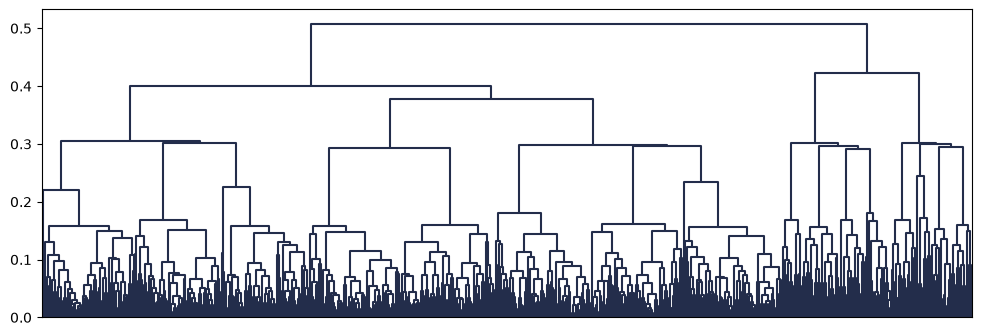

== drop sex: sizes [365, 324, 649]


,age,bmi,children
c,,,
1,38.94,33.33,1.06
2,39.27,29.17,1.05
3,39.33,29.91,1.14


sex,female,male
row_0,,
1,176,189
2,161,163
3,325,324


smoker,no,yes
row_0,,
1,274,91
2,257,67
3,533,116


region,northeast,northwest,southeast,southwest
row_0,,,,
1,0,1,364,0
2,324,0,0,0
3,0,324,0,325


== weights 0.5: sizes [10, 268, 1060]


,age,bmi,children
c,,,
1,33.10,28.36,5.00
2,38.10,30.81,1.12
3,39.55,30.65,1.05


sex,female,male
row_0,,
1,3,7
2,109,159
3,550,510


smoker,no,yes
row_0,,
1,9,1
2,0,268
3,1055,5


region,northeast,northwest,southeast,southwest
row_0,,,,
1,0,0,3,7
2,67,53,91,57
3,257,272,270,261


In [21]:
def describe(lab, title):
    print(f"== {title}: sizes {np.bincount(lab)[1:].tolist()}")
    display(ins.assign(c=lab).groupby('c')[ins_num].mean().round(2))
    for c in ins_cat: display(pd.crosstab(lab, ins[c]))

lab_avg, lab_comp = gower_clusters(G, 'average'), gower_clusters(G, 'complete')
describe(lab_avg, 'average'); describe(lab_comp, 'complete')

Zg = linkage(squareform(G, checks=False), method='average')
plt.figure(figsize=(12, 4)); dendrogram(Zg, no_labels=True, color_threshold=0, above_threshold_color='#232D4B'); plt.show()

G_nosex = gower_matrix(ins, ins_num, ['smoker', 'region'])
G_half = gower_matrix(ins, ins_num, ins_cat, weights={c: 0.5 for c in ins_cat})
lab_nosex, lab_half = gower_clusters(G_nosex, 'average'), gower_clusters(G_half, 'average')
describe(lab_nosex, 'drop sex'); describe(lab_half, 'weights 0.5')

- a) Smoker and sex decide the clusters. Age, BMI, children and region are the same in every cluster
b) A categorical mismatch adds a full 1/6 to the distance while a typical numeric difference adds only about 0.03–0.06. People who match on sex and smoker are always close no matter their age or BMI
c) Dropping sex makes region decide the clusters, so the issue just moves to another categorical variable. Weights of 0.5 give 1,060/268/10 and the 268 are all smokers and the 10 are people with 5 children. Smoker still dominates, but now at least a numerical variable shows up

### 3)

In [22]:
kp = KPrototypes(n_clusters=3, init="Huang", n_init=10, random_state=0).fit(X_mixed, categorical=cat_idx)
kp10 = KPrototypes(n_clusters=3, init="Huang", n_init=10, random_state=0, gamma=10).fit(X_mixed, categorical=cat_idx)
print("gamma:", kp.gamma)
describe(kp.labels_ + 1, 'K-proto default'); describe(kp10.labels_ + 1, 'K-proto gamma=10')

cent = np.asarray(kp.cluster_centroids_)
Xn = X_mixed[ins_num].to_numpy(dtype=float)
sq = ((Xn - cent[:, :3].astype(float)[kp.labels_])**2).sum(axis=1)
mis = sum((ins[c].to_numpy() != cent[kp.labels_, 3 + j]).astype(int) for j, c in enumerate(ins_cat))
print(sq.mean(), kp.gamma * mis.mean())

gamma: 0.5
== K-proto default: sizes [460, 387, 491]


,age,bmi,children
c,,,
1,52.77,31.56,0.47
2,40.18,30.90,2.67
3,25.73,29.64,0.44


sex,female,male
row_0,,
1,253,207
2,177,210
3,232,259


smoker,no,yes
row_0,,
1,378,82
2,301,86
3,385,106


region,northeast,northwest,southeast,southwest
row_0,,,,
1,127,98,118,117
2,82,112,96,97
3,115,115,150,111


== K-proto gamma=10: sizes [608, 459, 271]


,age,bmi,children
c,,,
1,42.03,30.44,1.13
2,34.27,29.10,0.97
3,41.24,33.81,1.23


sex,female,male
row_0,,
1,545,63
2,68,391
3,49,222


smoker,no,yes
row_0,,
1,553,55
2,428,31
3,83,188


region,northeast,northwest,southeast,southwest
row_0,,,,
1,153,227,139,89
2,125,69,51,214
3,46,29,174,22


1.622831460990806 0.6872197309417041


- a) gamma = 0.5. The clusters are decided by age and children: 460 people averaging 52.8 years, 387 averaging 2.67 children, and 491 averaging 25.7 years. Sex, smoker and region are about the same mix in each cluster
- b) With gamma = 10 the clusters follow the categorical variables. Cluster 3 is 84% male and 68% smokers (mostly southeast), and cluster 1 is 88% female
- c) The average squared numeric distance is 1.62, while one mismatch costs only 0.5. The average person's mismatches cost 0.69, so categorical differences are only about 30% of the total distance. So K prototypes is driven by the numeric variables and gower is driven by the categorical ones

### 4)

,n,mean,median,smokers
Gower avg,,,,
1,1064,8434.0,7345.0,0
2,159,33042.0,36085.0,159
3,115,30679.0,28950.0,115


,n,mean,median,smokers
Gower w=0.5,,,,
1,10,8692.0,6660.0,1
2,268,32112.0,34645.0,268
3,1060,8550.0,7395.0,5


,n,mean,median,smokers
K-proto default,,,,
0,460,16171.0,11753.0,82
1,387,14578.0,9302.0,86
2,491,9522.0,3867.0,106


,n,mean,median,smokers
K-proto γ=10,,,,
0,608,11082.0,9413.0,55
1,459,8093.0,5484.0,31
2,271,26949.0,25382.0,188


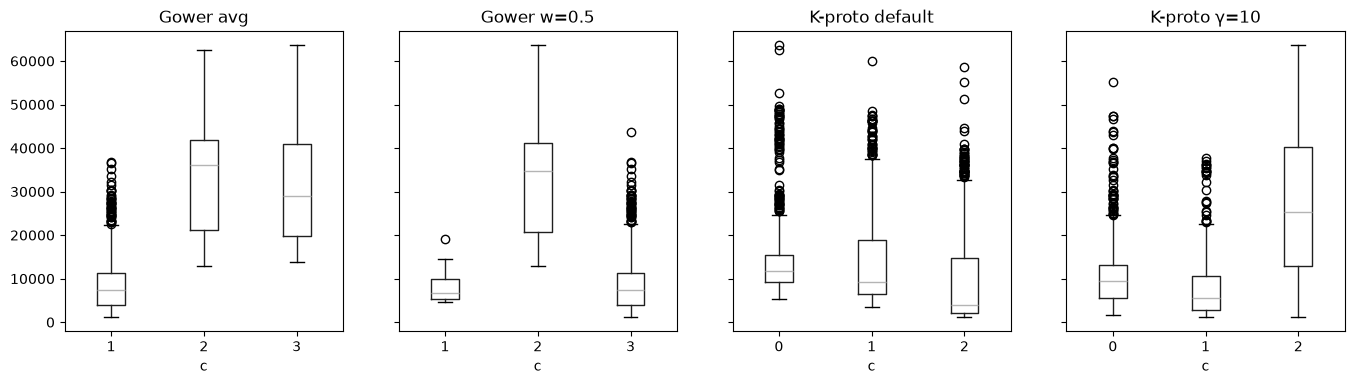

In [23]:
sols = {'Gower avg': lab_avg, 'Gower w=0.5': lab_half, 'K-proto default': kp.labels_, 'K-proto γ=10': kp10.labels_}
fig, axs = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (name, lab) in zip(axs, sols.items()):
    d_ = ins.assign(c=lab)
    display(d_.groupby('c').agg(n=('charges', 'size'), mean=('charges', 'mean'), median=('charges', 'median'),
                                smokers=('smoker', lambda x: (x == 'yes').sum())).round(0).rename_axis(name))
    d_.boxplot(column='charges', by='c', ax=ax, grid=False); ax.set_title(name)
plt.suptitle(''); plt.show()

- a) Gower with average linkage separates charges best. It isolates the smokers who drive charges but that doesn't make it the right clustering. Charges were never an input, so the clusters just happen to line up with one variable. The two smoker clusters differ only by sex (33k vs 30k) which adds little
- b) How much a categorical difference counts is arbitrary but it influences the result pretty heavily. I'd treat it as a modeling decision and check how sensitive the clusters are to it